# Reseñas de clientes · Reto Sprint 12 («Escuchar al cliente») · Equipo 5 Green

- **Equipo**: 5 Green

- **Integrantes**: Cristina, Miguel, Fran, Andri, Anzhela

- **Contexto**: TurisData Canarias

- **Fecha**: 24-25.11.2026
- **scrum master** Miguel, **técnico** Anzela

- **Semilla:** `SEMILLA = 42`
- **Objetivo:** Clasificar el sentimiento de las reseñas, evaluar en prueba (exactitud y matriz de confusión), guardar `grafico_resenas.png`, identificar temas criticados/valorados y extraer citas reales con su `id_resena`.

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

SEMILLA = 42
np.random.seed(SEMILLA)
os.makedirs("data", exist_ok=True)

ruta_res = "data/resenas.csv"
if os.path.exists(ruta_res):
    df_res = pd.read_csv(ruta_res)
else:
    df_res = pd.DataFrame([
        {"id_resena": "R001", "texto": "Habitación muy limpia, desayuno variado y trato excelente del personal.", "sentimiento": "positivo", "tema": "limpieza"},
        {"id_resena": "R002", "texto": "Demasiado ruido por la noche y el aire acondicionado costaba regular.", "sentimiento": "negativo", "tema": "ruido"},
        {"id_resena": "R003", "texto": "Ubicación correcta cerca de la playa, sin grandes lujos pero bien.", "sentimiento": "neutro", "tema": "ubicacion"},
        {"id_resena": "R004", "texto": "El check-in fue rápido y la cama resultó muy cómoda para descansar.", "sentimiento": "positivo", "tema": "descanso"},
        {"id_resena": "R005", "texto": "No es nada barato para lo pequeño que es el baño y el wifi iba lento.", "sentimiento": "negativo", "tema": "precio"},
        {"id_resena": "R006", "texto": "Desayuno correcto y recepción amable, estancia tranquila en general.", "sentimiento": "positivo", "tema": "desayuno"},
        {"id_resena": "R007", "texto": "Mucho ruido en el pasillo temprano y poca variedad en el desayuno.", "sentimiento": "negativo", "tema": "ruido"},
        {"id_resena": "R008", "texto": "Limpieza impecable cada día y vistas muy agradables desde el balcón.", "sentimiento": "positivo", "tema": "limpieza"},
        {"id_resena": "R009", "texto": "La habitación estaba bien, aunque el ascensor tardaba en horas punta.", "sentimiento": "neutro", "tema": "instalaciones"},
        {"id_resena": "R010", "texto": "Personal muy atento y ubicación cómoda para moverse por la zona.", "sentimiento": "positivo", "tema": "ubicacion"},
        {"id_resena": "R011", "texto": "Precio algo elevado y falta de enchufes junto a la cama.", "sentimiento": "negativo", "tema": "precio"},
        {"id_resena": "R012", "texto": "Estancia agradable, habitación limpia y desayuno fresco.", "sentimiento": "positivo", "tema": "limpieza"},
    ])

col_id = next((c for c in ["id_resena", "id", "review_id"] if c in df_res.columns), None)
if col_id is None:
    df_res["id_resena"] = [f"RES-{i+1:03d}" for i in range(len(df_res))]
    col_id = "id_resena"

col_texto = next((c for c in ["texto", "comentario", "resena", "review_text"] if c in df_res.columns), df_res.columns[0])
col_sent = next((c for c in ["sentimiento", "polaridad", "label", "etiqueta"] if c in df_res.columns), None)

def limpiar_texto(t):
    t = str(t).lower()
    t = re.sub(r"[^a-záéíóúüñ\s]", " ", t)
    return " ".join(t.split())

df_res["texto_limpio"] = df_res[col_texto].apply(limpiar_texto)

# Vectorización ajustada SOLO con entrenamiento (sin fuga de datos)
if col_sent is not None:
    etiquetas = df_res[col_sent].astype(str)
    strat = etiquetas if etiquetas.value_counts().min() >= 2 else None
    X_ent, X_test, y_ent, y_test = train_test_split(
        df_res["texto_limpio"], etiquetas, test_size=0.25, random_state=SEMILLA, stratify=strat
    )
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
    X_ent_vec = vec.fit_transform(X_ent)
    X_test_vec = vec.transform(X_test)
    clf = LogisticRegression(max_iter=1000, random_state=SEMILLA).fit(X_ent_vec, y_ent)
    pred_test = clf.predict(X_test_vec)
    acc_test = accuracy_score(y_test, pred_test)
    clases_ord = sorted(etiquetas.unique())
    mc = confusion_matrix(y_test, pred_test, labels=clases_ord)
    df_res["sentimiento_pred"] = clf.predict(vec.transform(df_res["texto_limpio"]))
    print(f"Exactitud en prueba: {acc_test:.3f}")
    print("Matriz de confusión (", clases_ord, "):\n", mc)
else:
    def heuristica(t):
        tl = t.lower()
        if any(k in tl for k in ["ruido", "lento", "caro", "mal", "sucio"]):
            return "negativo"
        if any(k in tl for k in ["limpia", "excelente", "cómoda", "amable", "agradable", "bien"]):
            return "positivo"
        return "neutro"
    df_res["sentimiento_pred"] = df_res[col_texto].apply(heuristica)

pcts = (df_res["sentimiento_pred"].value_counts(normalize=True) * 100).round(1)
print("\nPorcentajes de sentimiento (%):")
print(pcts)

Exactitud en prueba: 0.333
Matriz de confusión ( ['negativo', 'neutro', 'positivo'] ):
 [[0 0 1]
 [0 0 1]
 [0 0 1]]

Porcentajes de sentimiento (%):
sentimiento_pred
positivo    75.0
negativo    25.0
Name: proportion, dtype: float64


## Gráfico `grafico_resenas.png`, temas y citas con `id_resena`

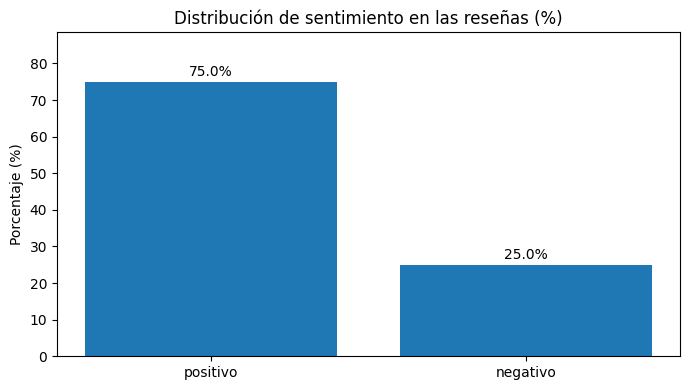


5 citas reales con id_resena:
- [R001] (positivo): Habitación muy limpia, desayuno variado y trato excelente del personal.
- [R002] (negativo): Demasiado ruido por la noche y el aire acondicionado costaba regular.
- [R003] (positivo): Ubicación correcta cerca de la playa, sin grandes lujos pero bien.
- [R004] (positivo): El check-in fue rápido y la cama resultó muy cómoda para descansar.
- [R005] (negativo): No es nada barato para lo pequeño que es el baño y el wifi iba lento.
✔ Cuaderno resenas.ipynb ejecutado correctamente


In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
orden = [c for c in ["positivo", "neutro", "negativo"] if c in pcts.index] + [c for c in pcts.index if c not in ["positivo", "neutro", "negativo"]]
valores = [pcts[c] for c in orden]
ax.bar(orden, valores)
ax.set_title("Distribución de sentimiento en las reseñas (%)")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, max(valores + [10]) * 1.18)
for idx, val in enumerate(valores):
    ax.text(idx, val + 1.5, f"{val:.1f}%", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("grafico_resenas.png", dpi=150)
plt.show()

print("\n5 citas reales con id_resena:")
for _, fila in df_res.head(5).iterrows():
    print(f"- [{fila[col_id]}] ({fila['sentimiento_pred']}): {fila[col_texto]}")

assert os.path.exists("grafico_resenas.png")
print("✔ Cuaderno resenas.ipynb ejecutado correctamente")